# Assignment 6: TwoLayerNet with numerical gradients on Iris and MNIST

In [1]:
import gzip
import inspect
import pickle
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from two_layer_net import TwoLayerNet

np.random.seed(42)

## TwoLayerNet class (from `two_layer_net.py`)

In [2]:
print(inspect.getsource(TwoLayerNet))

class TwoLayerNet:
    """Two-layer neural network trained with numerical gradients.

    Architecture: input -> hidden (sigmoid) -> output (softmax).
    The loss is the cross-entropy error, and the gradient of the loss with
    respect to every weight and bias is found by central differences.
    """

    def __init__(self, input_size, hidden_size, output_size, weight_init_std=0.01):
        self.params = {}
        self.params['W1'] = weight_init_std * np.random.randn(input_size, hidden_size)
        self.params['b1'] = np.zeros(hidden_size)
        self.params['W2'] = weight_init_std * np.random.randn(hidden_size, output_size)
        self.params['b2'] = np.zeros(output_size)

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def softmax(self, x):
        x = x - np.max(x, axis=-1, keepdims=True)  # avoid overflow
        return np.exp(x) / np.sum(np.exp(x), axis=-1, keepdims=True)

    def cross_entropy_error(self, y, t):
        if y.ndim == 1:
            y = y.

# Part 1: Iris - load the train and test data

In [3]:
iris_train = pd.read_csv('Part 1/iris/iris_train.csv')
iris_test = pd.read_csv('Part 1/iris/iris_test.csv')

features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
iris_classes = ['setosa', 'versicolor', 'virginica']

x_train_iris = iris_train[features].values
t_train_iris = np.eye(3)[iris_train['label'].values]  # one-hot labels
x_test_iris = iris_test[features].values
t_test_iris = iris_test['label'].values

print('x_train:', x_train_iris.shape, ' t_train:', t_train_iris.shape)
print('x_test: ', x_test_iris.shape, ' t_test: ', t_test_iris.shape)
iris_train.head()

x_train: (120, 4)  t_train: (120, 3)
x_test:  (30, 4)  t_test:  (30,)


,sepal_length,sepal_width,petal_length,petal_width,label,species
0,4.4,2.9,1.4,0.2,0,setosa
1,4.9,2.5,4.5,1.7,2,virginica
2,6.8,2.8,4.8,1.4,1,versicolor
3,4.9,3.1,1.5,0.1,0,setosa
4,5.5,2.5,4.0,1.3,1,versicolor


## Train a 4-10-3 network on Iris

In [4]:
iris_net = TwoLayerNet(input_size=4, hidden_size=10, output_size=3)

epochs = 1000
learning_rate = 0.1
iris_loss_list, iris_train_acc_list, iris_test_acc_list = [], [], []

start = time.time()
for epoch in range(1, epochs + 1):
    grads = iris_net.numerical_gradient(x_train_iris, t_train_iris)
    for key in ('W1', 'b1', 'W2', 'b2'):
        iris_net.params[key] -= learning_rate * grads[key]

    iris_loss_list.append(iris_net.loss(x_train_iris, t_train_iris))
    iris_train_acc_list.append(iris_net.accuracy(x_train_iris, t_train_iris))
    iris_test_acc_list.append(iris_net.accuracy(x_test_iris, t_test_iris))

    if epoch == 1 or epoch % 100 == 0:
        print(f'Epoch {epoch:4d} | loss {iris_loss_list[-1]:.4f} | '
              f'train acc {iris_train_acc_list[-1]:.4f} | test acc {iris_test_acc_list[-1]:.4f}')

print(f'Training time: {time.time() - start:.1f} s')

Epoch    1 | loss 1.0987 | train acc 0.3333 | test acc 0.3333


Epoch  100 | loss 1.0833 | train acc 0.6750 | test acc 0.6667


Epoch  200 | loss 0.7605 | train acc 0.6917 | test acc 0.7333


Epoch  300 | loss 0.4927 | train acc 0.9000 | test acc 0.9000


Epoch  400 | loss 0.3986 | train acc 0.9667 | test acc 0.9667


Epoch  500 | loss 0.3255 | train acc 0.9750 | test acc 1.0000


Epoch  600 | loss 0.2674 | train acc 0.9750 | test acc 1.0000


Epoch  700 | loss 0.2239 | train acc 0.9750 | test acc 1.0000


Epoch  800 | loss 0.1921 | train acc 0.9833 | test acc 1.0000


Epoch  900 | loss 0.1687 | train acc 0.9833 | test acc 1.0000


Epoch 1000 | loss 0.1511 | train acc 0.9750 | test acc 1.0000
Training time: 7.0 s


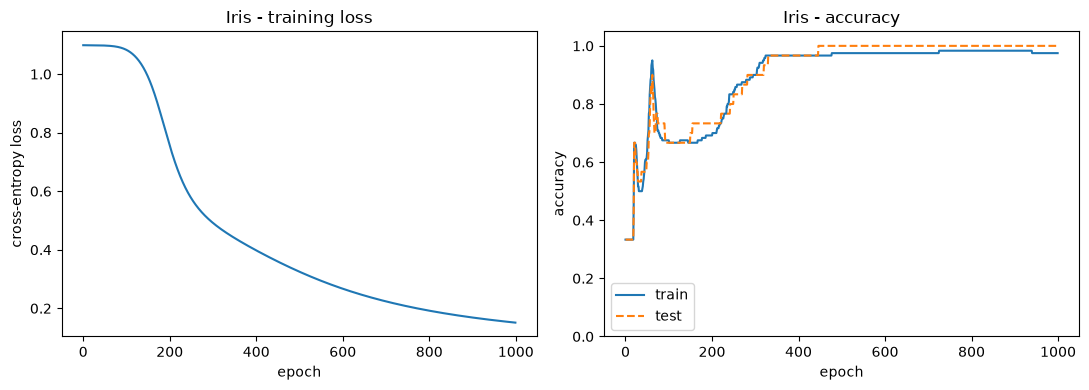

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(iris_loss_list)
ax1.set_title('Iris - training loss')
ax1.set_xlabel('epoch')
ax1.set_ylabel('cross-entropy loss')

ax2.plot(iris_train_acc_list, label='train')
ax2.plot(iris_test_acc_list, label='test', linestyle='--')
ax2.set_title('Iris - accuracy')
ax2.set_xlabel('epoch')
ax2.set_ylabel('accuracy')
ax2.set_ylim(0, 1.05)
ax2.legend()
plt.tight_layout()
plt.show()

## Save the trained Iris network

In [6]:
with open('joshi_iris_nn_model.pkl', 'wb') as f:
    pickle.dump(iris_net, f)
print('Saved joshi_iris_nn_model.pkl')

Saved joshi_iris_nn_model.pkl


## Load the saved network and test on Iris

In [7]:
with open('joshi_iris_nn_model.pkl', 'rb') as f:
    loaded_iris_net = pickle.load(f)

y_iris = np.argmax(loaded_iris_net.predict(x_test_iris), axis=1)

print(f'{"#":>3}  {"Actual":<12}{"Predicted":<12}Result')
print('-' * 38)
for i, (actual, pred) in enumerate(zip(t_test_iris, y_iris)):
    result = 'correct' if actual == pred else 'incorrect'
    print(f'{i:>3}  {iris_classes[actual]:<12}{iris_classes[pred]:<12}{result}')

n_correct = np.sum(y_iris == t_test_iris)
print('-' * 38)
print(f'Iris test accuracy: {n_correct}/{len(t_test_iris)} = {n_correct / len(t_test_iris):.2%}')

  #  Actual      Predicted   Result
--------------------------------------
  0  setosa      setosa      correct
  1  virginica   virginica   correct
  2  versicolor  versicolor  correct
  3  versicolor  versicolor  correct
  4  setosa      setosa      correct
  5  versicolor  versicolor  correct
  6  setosa      setosa      correct
  7  setosa      setosa      correct
  8  virginica   virginica   correct
  9  versicolor  versicolor  correct
 10  virginica   virginica   correct
 11  virginica   virginica   correct
 12  virginica   virginica   correct
 13  versicolor  versicolor  correct
 14  setosa      setosa      correct
 15  setosa      setosa      correct
 16  setosa      setosa      correct
 17  versicolor  versicolor  correct
 18  versicolor  versicolor  correct
 19  virginica   virginica   correct
 20  setosa      setosa      correct
 21  virginica   virginica   correct
 22  versicolor  versicolor  correct
 23  virginica   virginica   correct
 24  virginica   virginica   correct


# Part 2: MNIST - load the train and test data

In [8]:
def load_mnist_images(path):
    with gzip.open(path, 'rb') as f:
        data = np.frombuffer(f.read(), np.uint8, offset=16)
    return data.reshape(-1, 784).astype(np.float64) / 255.0

def load_mnist_labels(path):
    with gzip.open(path, 'rb') as f:
        return np.frombuffer(f.read(), np.uint8, offset=8).astype(np.int64)

x_train_mnist = load_mnist_images('Part 2/mnist/train-images-idx3-ubyte.gz')
t_train_mnist = load_mnist_labels('Part 2/mnist/train-labels-idx1-ubyte.gz')
x_test_mnist = load_mnist_images('Part 2/mnist/t10k-images-idx3-ubyte.gz')
t_test_mnist = load_mnist_labels('Part 2/mnist/t10k-labels-idx1-ubyte.gz')

print('x_train:', x_train_mnist.shape, ' t_train:', t_train_mnist.shape)
print('x_test: ', x_test_mnist.shape, ' t_test: ', t_test_mnist.shape)

x_train: (60000, 784)  t_train: (60000,)
x_test:  (10000, 784)  t_test:  (10000,)


## Train a 784-10-10 network on MNIST

In [9]:
mnist_net = TwoLayerNet(input_size=784, hidden_size=10, output_size=10)

iters_num = 300
batch_size = 50
learning_rate = 1.0
eval_interval = 25
train_size = x_train_mnist.shape[0]

mnist_loss_list, mnist_eval_iters, mnist_train_acc_list, mnist_test_acc_list = [], [], [], []

start = time.time()
for i in range(1, iters_num + 1):
    batch_mask = np.random.choice(train_size, batch_size)
    x_batch = x_train_mnist[batch_mask]
    t_batch = np.eye(10)[t_train_mnist[batch_mask]]  # one-hot labels

    grads = mnist_net.numerical_gradient(x_batch, t_batch)
    for key in ('W1', 'b1', 'W2', 'b2'):
        mnist_net.params[key] -= learning_rate * grads[key]

    mnist_loss_list.append(mnist_net.loss(x_batch, t_batch))

    if i == 1 or i % eval_interval == 0:
        train_acc = mnist_net.accuracy(x_train_mnist, t_train_mnist)
        test_acc = mnist_net.accuracy(x_test_mnist, t_test_mnist)
        mnist_eval_iters.append(i)
        mnist_train_acc_list.append(train_acc)
        mnist_test_acc_list.append(test_acc)
        print(f'Iter {i:3d} | batch loss {mnist_loss_list[-1]:.4f} | '
              f'train acc {train_acc:.4f} | test acc {test_acc:.4f} | '
              f'elapsed {time.time() - start:6.1f} s')

print(f'Training time: {(time.time() - start) / 60:.1f} min')

Iter   1 | batch loss 2.2102 | train acc 0.1124 | test acc 0.1135 | elapsed    1.2 s


Iter  25 | batch loss 2.1910 | train acc 0.2603 | test acc 0.2653 | elapsed   26.0 s


Iter  50 | batch loss 1.7851 | train acc 0.4011 | test acc 0.4027 | elapsed   51.7 s


Iter  75 | batch loss 1.3114 | train acc 0.5925 | test acc 0.5943 | elapsed   77.4 s


Iter 100 | batch loss 0.8523 | train acc 0.7372 | test acc 0.7405 | elapsed  103.0 s


Iter 125 | batch loss 0.6273 | train acc 0.7650 | test acc 0.7680 | elapsed  128.5 s


... (3 outputs left out)

Iter 225 | batch loss 0.4901 | train acc 0.8571 | test acc 0.8616 | elapsed  231.0 s


Iter 250 | batch loss 0.3072 | train acc 0.8749 | test acc 0.8763 | elapsed  256.5 s


Iter 275 | batch loss 0.3540 | train acc 0.8782 | test acc 0.8796 | elapsed  282.2 s


Iter 300 | batch loss 0.2332 | train acc 0.8720 | test acc 0.8760 | elapsed  307.8 s
Training time: 5.1 min


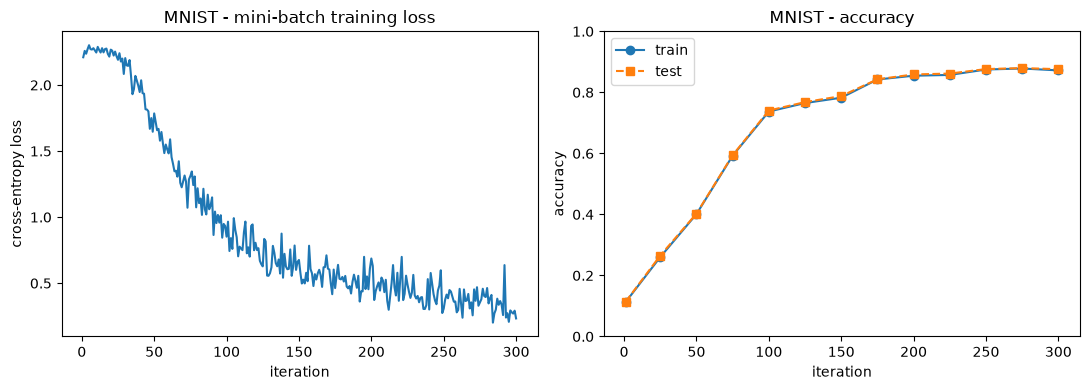

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(range(1, len(mnist_loss_list) + 1), mnist_loss_list)
ax1.set_title('MNIST - mini-batch training loss')
ax1.set_xlabel('iteration')
ax1.set_ylabel('cross-entropy loss')

ax2.plot(mnist_eval_iters, mnist_train_acc_list, marker='o', label='train')
ax2.plot(mnist_eval_iters, mnist_test_acc_list, marker='s', linestyle='--', label='test')
ax2.set_title('MNIST - accuracy')
ax2.set_xlabel('iteration')
ax2.set_ylabel('accuracy')
ax2.set_ylim(0, 1.0)
ax2.legend()
plt.tight_layout()
plt.show()

## Save the trained MNIST network

In [11]:
with open('joshi_mnist_nn_model.pkl', 'wb') as f:
    pickle.dump(mnist_net, f)
print('Saved joshi_mnist_nn_model.pkl')

Saved joshi_mnist_nn_model.pkl


## Load the saved network and test on MNIST

In [12]:
with open('joshi_mnist_nn_model.pkl', 'rb') as f:
    loaded_mnist_net = pickle.load(f)

y_mnist = np.argmax(loaded_mnist_net.predict(x_test_mnist), axis=1)
n_correct = np.sum(y_mnist == t_test_mnist)
print(f'MNIST test accuracy: {n_correct}/{len(t_test_mnist)} = {n_correct / len(t_test_mnist):.2%}')

MNIST test accuracy: 8760/10000 = 87.60%


## Actual vs. predicted for the first 30 test samples

In [13]:
print(f'{"#":>3}  {"Actual":<8}{"Predicted":<11}Result')
print('-' * 32)
for i in range(30):
    actual, pred = t_test_mnist[i], y_mnist[i]
    result = 'correct' if actual == pred else 'incorrect'
    print(f'{i:>3}  {actual:<8}{pred:<11}{result}')

  #  Actual  Predicted  Result
--------------------------------
  0  7       7          correct
  1  2       2          correct
  2  1       1          correct
  3  0       0          correct
  4  4       4          correct
  5  1       1          correct
  6  4       4          correct
  7  9       9          correct
  8  5       6          incorrect
  9  9       7          incorrect
 10  0       0          correct
 11  6       6          correct
 12  9       9          correct
 13  0       0          correct
 14  1       1          correct
 15  5       5          correct
 16  9       9          correct
 17  7       7          correct
 18  3       6          incorrect
 19  4       4          correct
 20  9       7          incorrect
 21  6       6          correct
 22  6       6          correct
 23  5       5          correct
 24  4       4          correct
 25  0       0          correct
 26  7       7          correct
 27  4       4          correct
 28  0       0          correct


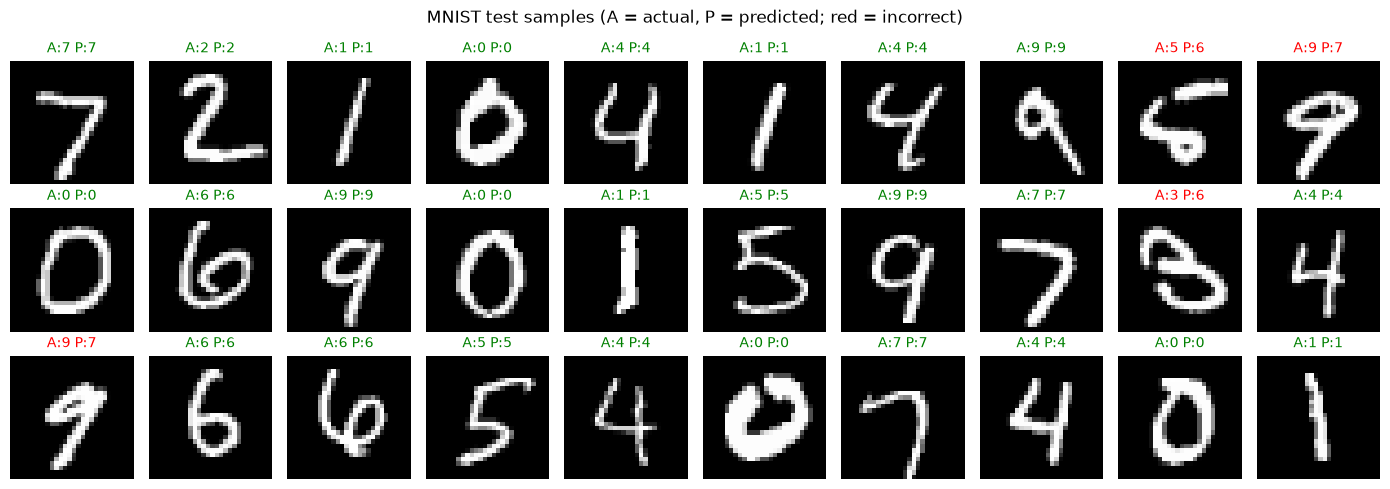

In [14]:
fig, axes = plt.subplots(3, 10, figsize=(14, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test_mnist[i].reshape(28, 28), cmap='gray')
    ok = t_test_mnist[i] == y_mnist[i]
    ax.set_title(f'A:{t_test_mnist[i]} P:{y_mnist[i]}', color='green' if ok else 'red', fontsize=10)
    ax.axis('off')
fig.suptitle('MNIST test samples (A = actual, P = predicted; red = incorrect)')
plt.tight_layout()
plt.show()

## Accuracy per digit

In [15]:
print(f'{"Digit":<7}{"Correct":>8}{"Total":>8}{"Accuracy":>10}')
for d in range(10):
    mask = t_test_mnist == d
    c = np.sum(y_mnist[mask] == d)
    print(f'{d:<7}{c:>8}{mask.sum():>8}{c / mask.sum():>10.2%}')

Digit   Correct   Total  Accuracy
0           947     980    96.63%
1          1113    1135    98.06%
2           894    1032    86.63%
3           886    1010    87.72%
4           814     982    82.89%
5           684     892    76.68%
6           900     958    93.95%
7           977    1028    95.04%
8           823     974    84.50%
9           722    1009    71.56%
